# PyTorch Neural Network Classification

A classification problem involves predicting whether something is one thing or another.

## Architecture of a Classification Neural Network

| Hyperparameter | Binary Classification | Multiclass classification |
|---|---|---|
| Input layer shape (`in_features`) | Same as number of features (e.g. 5 for age, sex, height, weight, smoking status in heart disease prediction) | Same as binary classification |
| Hidden layer(s) | Problem specific, minimum = 1, maximum = unlimited | Same as binary classification |
| Neurons per hidden layer | Problem specific, generally 10 to 512 | Same as binary classification |
| Output layer shape (`out_features`) | 1 (one class or the other) | 1 per class (e.g. 3 for food, person or dog photo) |
| Hidden layer activation | Usually [ReLU](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html) (rectified linear unit) but can be many others | Same as binary classification |
| Output activation | Sigmoid (`torch.sigmoid` in PyTorch) | Softmax (`torch.softmax` in PyTorch) |
| Loss function | Binary crossentropy (`torch.nn.BCELoss` in PyTorch) | Cross entropy (`torch.nn.CrossEntropyLoss` in PyTorch) |
| Optimizer | SGD (stochastic gradient descent), Adam (see `torch.optim` for more options) | Same as binary classification |


Of course, this ingredient list of classification nerual network comonents will vary depending on the problem we're working on. \
However, it's more than enough to get started. \
We're going to get hands-on with this setup throughout this notebook.

## Make Classification Data and Get it Ready

Let's begin by making some data. We'll use the `make-circles()` method from Scikit-Learn to generate two circles with different coloured dots

In [3]:
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples, noise=0.03, random_state=69)

print(f'\nfirst features of X: {X[:5]}')
print(f'\nfirst 5 labels: {y[:5]}')


first features of X: [[-0.51839217 -0.66522091]
 [ 0.78398275 -0.00098577]
 [ 0.12616247 -0.75963138]
 [-0.70384469 -0.32717022]
 [ 0.67524498 -0.34785267]]

first 5 labels: [1 1 1 1 1]


In [8]:
import pandas as pd

circles = pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "label": y})
circles.head(5)

,X1,X2,label
0,-0.518392,-0.665221,1
1,0.783983,-0.000986,1
2,0.126162,-0.759631,1
3,-0.703845,-0.327170,1
4,0.675245,-0.347853,1


In [12]:
circles.label.value_counts()

label
1    500
0    500
Name: count, dtype: int64

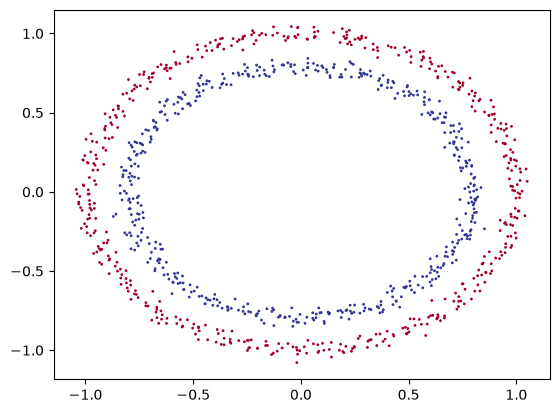

In [15]:
from matplotlib import pyplot as plt

plt.scatter(x=X[:,0], y=X[:,1], c=y, s=1, cmap=plt.cm.RdYlBu)

### _Input and Output shapes_

One of the most common errors in deep leanring is shape errors. \
Mismatching the shapes of tensors and tensor operations will result in erros in our models. \
We're going to see plenty of these throughout the course. \
And there is no surefire way to make sure they won't happen, they will. \
What we can do instead is continually familiarize ourselves with the shape of the data we're working with. \
I like referring to it as inpu and output shapes.

Ask ourselves: "What shapes are the inputs and what shapes are the outputs.

In [11]:
import numpy as np

sa = np.random.randint(1, 10, (10,10))

sa, sa[len(sa)-5:]

(array([[4, 2, 6, 1, 7, 4, 4, 6, 9, 4],
        [2, 9, 8, 5, 3, 3, 4, 6, 4, 4],
        [5, 6, 3, 4, 6, 2, 6, 2, 9, 2],
        [1, 4, 3, 9, 6, 9, 2, 5, 6, 8],
        [8, 6, 6, 7, 1, 5, 2, 4, 2, 3],
        [9, 2, 1, 2, 9, 5, 8, 1, 5, 4],
        [3, 2, 5, 2, 1, 5, 8, 7, 5, 7],
        [6, 1, 6, 1, 9, 6, 6, 7, 3, 6],
        [4, 1, 2, 4, 8, 4, 3, 1, 7, 1],
        [1, 8, 7, 8, 6, 7, 7, 2, 2, 4]]),
 array([[9, 2, 1, 2, 9, 5, 8, 1, 5, 4],
        [3, 2, 5, 2, 1, 5, 8, 7, 5, 7],
        [6, 1, 6, 1, 9, 6, 6, 7, 3, 6],
        [4, 1, 2, 4, 8, 4, 3, 1, 7, 1],
        [1, 8, 7, 8, 6, 7, 7, 2, 2, 4]]))